# 01 · The data: invoices, payments and why matching is hard

**Cash application** is the accounts-receivable job of working out which open invoice(s) each incoming payment pays, then posting it. Until it's done the cash sits as *unapplied*: customers look overdue when they're not, collectors chase the wrong people, and DSO is overstated.

This notebook looks at the synthetic dataset (`src/generate_data.py`) and the messiness the matcher has to cope with.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 160)
BLUE, ORANGE, AQUA, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3df", "figure.dpi": 100})
from generate_data import generate
DATA = ROOT / "data"
if not (DATA / "payments.csv").exists():
    import subprocess; subprocess.run([sys.executable, str(ROOT / "src/generate_data.py"), "--out", str(DATA)], check=True)
cust = pd.read_csv(DATA / "customers.csv")
inv = pd.read_csv(DATA / "invoices.csv", parse_dates=["issue_date", "due_date"], dtype={"po_number": str})
pay = pd.read_csv(DATA / "payments.csv", parse_dates=["payment_date"], keep_default_na=False)
matches = pd.read_csv(DATA / "matches.csv")
print(f"{len(cust)} customers | {len(inv):,} invoices | {len(pay):,} payments | {len(matches):,} payment-invoice links")

320 customers | 10,565 invoices | 8,549 payments | 10,640 payment-invoice links


## The four tables
The customer master and invoices come from the ERP; payments come from the bank (lockbox / BAI2 / camt.053 file). `matches.csv` is the ground truth an analyst would have produced.

In [2]:
display(cust.head(3)); display(inv.head(3)); display(pay.sample(8, random_state=1)[['payment_id','payment_date','amount','payer_name','remittance_text','payment_type']])

,customer_id,customer_name
0,C1000,Evergreen Textiles Corporation
1,C1001,Valley Retail Co
2,C1002,Trident Retail Ltd


,invoice_number,customer_id,po_number,amount,issue_date,due_date
0,INV-100000,C1125,4255460,20714.92,2025-01-01,2025-03-02
1,INV-100001,C1086,4824261,11000.50,2025-01-01,2025-02-15
2,INV-100002,C1178,4461251,846.70,2025-01-01,2025-03-02


,payment_id,payment_date,amount,payer_name,remittance_text,payment_type
8229,P008230,2026-01-18,3722.91,Cascade Chemicals,Pmt for INV110008,wire_fee
4193,P004194,2025-08-05,7588.95,Pacific Office Solutions CRRP,,exact
4268,P004269,2025-08-08,8139.84,LIBERTY CHEMICLAS,ACCOUNT SETTLEMENT,exact
5289,P005290,2025-09-17,8497.92,Quantum Construction,/RFB/PO 4791561,exact
5142,P005143,2025-09-11,2908.05,VALLEY OFFICE SOLU,RMT INV 106746,deduction
7223,P007224,2025-12-05,5000.00,Trident eTxtiles,REF INV 109311,exact
397,P000398,2025-03-01,2790.76,QUANTUM FOODS DISG CORP,Pmt for INV-101091,exact
7154,P007155,2025-12-02,500.00,VALLEY INDUSTRIAL SUPPLIES,Pmt for INV-108525,exact


## Payment types
About 60 % of payments are the easy case (one invoice, exact amount). The rest are what keeps cash-app analysts busy.

In [3]:
mix = pay.payment_type.value_counts()
explain = {"exact": "one invoice, exact amount", "combined": "several invoices in one payment",
           "partial": "one invoice paid in two parts", "wire_fee": "short by a bank fee (15-45)",
           "discount": "2 % early-pay discount taken", "deduction": "short 4-20 % (dispute, damage, rebate)",
           "unapplied": "no invoice at all (prepayment, unknown payer)", "combined_short": "combined + discount"}
display(pd.DataFrame({"payments": mix, "share": (mix / len(pay)).round(3), "meaning": mix.index.map(explain)}))

,payments,share,meaning
payment_type,,,
exact,5022,0.587,"one invoice, exact amount"
combined,993,0.116,several invoices in one payment
partial,774,0.091,one invoice paid in two parts
wire_fee,530,0.062,short by a bank fee (15-45)
discount,381,0.045,2 % early-pay discount taken
deduction,358,0.042,"short 4-20 % (dispute, damage, rebate)"
unapplied,328,0.038,"no invoice at all (prepayment, unknown payer)"
combined_short,163,0.019,combined + discount


## Messy payer names
The bank shows whatever the payer's bank sends: upper-case, truncated to 16-22 characters, abbreviated, misspelt, or a third-party processor.

In [4]:
ex = pay[pay.true_customer_id != ""].merge(cust, left_on="true_customer_id", right_on="customer_id")
from text import name_similarity, normalize_name
ex["exact_name"] = ex.payer_name.str.upper() == ex.customer_name.str.upper()
ex["similarity"] = [name_similarity(a, b) for a, b in zip(ex.payer_name, ex.customer_name)]
print(f"Payer name identical to the customer master: {ex.exact_name.mean():.1%} of payments")
display(ex.sample(10, random_state=4)[["payer_name", "customer_name", "similarity"]])

Payer name identical to the customer master: 20.0% of payments


,payer_name,customer_name,similarity
7268,NOVA ELECTRONICS,Nova Electronics Ltd,100.0
8285,Valley Industrial Supplies Pty Ltd,Valley Industrial Supplies Pty Ltd,100.0
3125,CRESCENT OFFICE SOLUTIONS,Crescent Office Solutions GmbH,100.0
9,Granite Auto Parts LLC,Granite Auto Parts LLC,100.0
1222,ACH CREDIT,Apex Office Solutions Inc,0.0
2192,SUMMITZFOODS DISTRIBUTION PTY LTD,Summit Foods Distribution Pty Ltd,91.2
5017,DELTA FOODS DISTRI,Delta Foods Distribution Limited,95.0
4934,CRESCENT LABORATORIES,Crescent Laboratories Limited,100.0
5063,HIGHLAND TEXTILES,Highland Textiles Corporation,100.0
949,PRAIRIE LOGISTIC,Prairie Logistics Limited,100.0


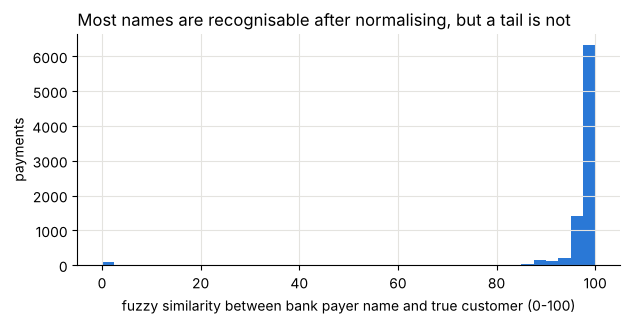

In [5]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(ex.similarity, bins=40, color=BLUE)
ax.set_xlabel("fuzzy similarity between bank payer name and true customer (0-100)"); ax.set_ylabel("payments")
ax.set_title("Most names are recognisable after normalising, but a tail is not", loc="left"); plt.show()

## Look-alike customers
320 customers are built from only 40 prefixes and 18 industries, so names overlap heavily ("Acme Chemicals LLC", "Acme Retail GmbH", "Summit Foods Inc" vs "Summit Foods Distribution LLC"). A truncated payer name like "ACME" fits many customers, so the best name match isn't always right.

In [6]:
first = cust.customer_name.str.split().str[0]
dup = cust[first.isin(first.value_counts()[lambda s: s >= 2].index)].sort_values("customer_name")
print(f"{len(cust)} customers, {first.nunique()} distinct first words: on average each first word is shared by {len(cust) / first.nunique():.0f} customers")
display(dup.head(8))

320 customers, 40 distinct first words: on average each first word is shared by 8 customers


,customer_id,customer_name
308,C1308,Acme Chemicals LLC
64,C1064,Acme Electronics Ltd
3,C1003,Acme Engineering Holdings
135,C1135,Acme Industrial Supplies Inc
268,C1268,Acme Logistics Co
171,C1171,Acme Retail GmbH
243,C1243,Apex Chemicals Holdings
73,C1073,Apex Industrial Supplies LLC


## Remittance text
Some payers quote the full invoice number, some only the last 4 digits, the PO number, a number with a typo, or nothing at all.

In [7]:
from text import extract_refs
r = pay.remittance_text.apply(extract_refs)
kinds = pd.DataFrame({"full invoice number": r.apply(lambda x: bool(x["invoice_digits"])),
                      "4-digit fragment": r.apply(lambda x: bool(x["fragments"])),
                      "PO number": r.apply(lambda x: bool(x["po_numbers"]))})
kinds["no usable reference"] = ~kinds.any(axis=1)
display(kinds.mean().round(3).rename("share of payments").to_frame())
display(pay[kinds["no usable reference"]].sample(6, random_state=2)[["payer_name", "remittance_text", "amount"]])

,share of payments
full invoice number,0.643
4-digit fragment,0.122
PO number,0.074
no usable reference,0.206


,payer_name,remittance_text,amount
6818,Evergreen LaboratFries,THANK YOU,500.50
1857,GRANITE TRADING,PAYMENT,3609.74
6456,UNION AUTO PARTS,INVOICES INV 018307,1000.00
7583,Golden Gate Industrial Supplies,PAYMENT INV 019207,980.00
5625,AMEX SETTLEMENT,AP PAYMENT RUN,847.60
7274,OrionYAuto Parts,REF INV 018847,13465.81


## Timing
Customers pay around the due date with customer-specific lateness. Combined payments skew later because the customer waits to batch invoices.

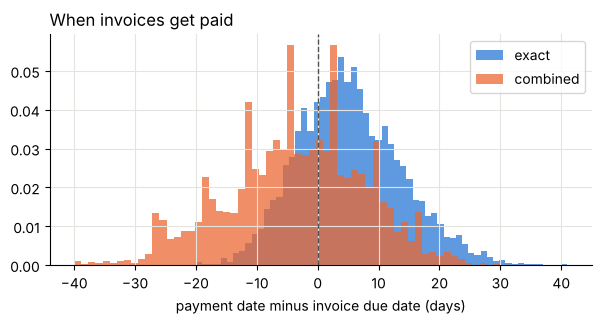

In [8]:
m = matches.merge(pay[["payment_id", "payment_date", "payment_type"]]).merge(inv[["invoice_number", "due_date"]])
m["days_from_due"] = (m.payment_date - m.due_date).dt.days
fig, ax = plt.subplots(figsize=(7, 3))
for t, col in [("exact", BLUE), ("combined", ORANGE)]:
    ax.hist(m.loc[m.payment_type == t, "days_from_due"].clip(-40, 80), bins=60, alpha=0.75, color=col, label=t, density=True)
ax.axvline(0, color=MUTED, ls="--", lw=1); ax.legend(); ax.set_xlabel("payment date minus invoice due date (days)")
ax.set_title("When invoices get paid", loc="left"); plt.show()

## Ambiguous amounts
15 % of invoices are round subscription-style amounts (500, 1,000, 2,500 ...), so amount alone often points at several invoices across customers.

In [9]:
vc = inv.amount.value_counts()
print(f"Invoices whose amount appears on 10+ other invoices: {inv.amount.map(vc).gt(10).mean():.1%}")
display(vc.head(6).rename("invoices with this amount").to_frame())

Invoices whose amount appears on 10+ other invoices: 15.5%


,invoices with this amount
amount,
2500.00,351
500.00,346
1500.00,341
5000.00,306
1000.00,298
772.05,2


## Takeaways for modelling
* No single signal is enough: references are missing on ~20 % of payments, names are fuzzy, amounts are ambiguous.
* Payments can map to **many** invoices (combined), and invoices to many payments (partials), so this is a *set* prediction, not a one-to-one lookup.
* The approach (notebook 02): **candidate generation** (cheap, high recall) → **pairwise match scoring** (gradient boosting) → **decision layer** (auto-match only when confident *and* amounts reconcile).